# 6BUIS017W CRM & CM With Business Intelligence
## Individual Coursework CWK1: Market Analysis and Stock Segmentation Using RFM
**Student Name / ID:** Candidate Submission  
**Module Leader:** Dr Panagiotis Chountas  
**Institution:** University of Westminster, School of Computer Science & Engineering  
**Observation Date:** 2024-12-31 (Final completed trading session of 2024)  
**Study Window:** 2021-01-01 to 2025-01-01 (Daily prices, volume, and ^GSPC benchmark)


### 1. Environment Setup & Dependency Installation
We import standard data science libraries for tabular data manipulation, statistical modeling, clustering, and visual diagnostics.
Package versions are logged to ensure full computational reproducibility.


In [1]:
# Run in Colab if packages need installation:
# !pip install yfinance pandas numpy scipy scikit-learn matplotlib seaborn

import sys
import os
import pickle
import datetime
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

print(f"Python Environment: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__} | Scikit-Learn: {__import__('sklearn').__version__} | yfinance: {yf.__version__}")


Python Environment: 3.11.5
Pandas: 3.1.1 | NumPy: 2.4.6 | Scikit-Learn: 1.9.1 | yfinance: 1.8.0


### 2. Task 1.1: Ticker Selection and Data Acquisition
We scrape the S&P 500 constituent table from Wikipedia, sanitize ticker symbols for Yahoo Finance compatibility (e.g., converting `BRK.B` to `BRK-B`), and download daily market data from 2021-01-01 to 2025-01-01 (exclusive).


In [2]:
from src.data_pipeline import scrape_sp500_tickers, download_market_data, STUDY_START, STUDY_END, BENCHMARK_TICKER, OBSERVATION_DATE

constituents = scrape_sp500_tickers()
print(f"Total Constituents Extracted: {len(constituents)}")
print(f"Extraction Timestamp: {constituents['Retrieval_Date'].iloc[0]}")
constituents.head()


Total Constituents Extracted: 503
Extraction Timestamp: 2026-11-19 17:17:36 UTC


,Ticker,Company,GICS_Sector,GICS_Sub_Industry,Headquarters Location,Date added,CIK,Founded,Clean_Ticker,Retrieval_Date
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM,2026-11-19 17:17:36 UTC
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS,2026-11-19 17:17:36 UTC
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT,2026-11-19 17:17:36 UTC
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV,2026-11-19 17:17:36 UTC
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN,2026-11-19 17:17:36 UTC


In [3]:
tickers = constituents["Clean_Ticker"].tolist()
raw_data = download_market_data(tickers, start=STUDY_START, end=STUDY_END)
print("Raw market data loaded successfully.")


Loading cached raw market data from data/market_data_raw.pkl...
Raw market data loaded successfully.


### 3. Task 1.2: Data Validation, Alignment & Survivorship Bias
We enforce quality checks:
1. Sufficient trading history: At least 80% valid trading days (minimum 804 days).
2. Absence of zero/negative prices or non-existent volume.
3. Existence of at least one qualifying high-volume event across the 4-year history.
4. Explicit logging of all excluded equities in `data/exclusion_log.csv`.
5. **Survivorship Bias:** Because we evaluate current S&P 500 constituents against 2021–2024 history, companies that were delisted, acquired, or went bankrupt during the period are excluded. This creates an upward survivorship bias that is critically accounted for.


In [4]:
exclusion_df = pd.read_csv("data/exclusion_log.csv")
print(f"Total Exclusions: {len(exclusion_df)}")
display(exclusion_df.value_counts("Reason"))
exclusion_df.head(10)


Total Exclusions: 12


Reason
Empty price history                                                     5
Insufficient trading history (742 days < 804 required 80% threshold)    1
Insufficient trading history (513 days < 804 required 80% threshold)    1
Insufficient trading history (193 days < 804 required 80% threshold)    1
Insufficient trading history (197 days < 804 required 80% threshold)    1
Insufficient trading history (194 days < 804 required 80% threshold)    1
No qualifying high-volume event found in study history                  1
Insufficient trading history (313 days < 804 required 80% threshold)    1
Name: count, dtype: int64

,Ticker,Reason
0,CEG,Insufficient trading history (742 days < 804 r...
1,FDXF,Empty price history
2,GEHC,Insufficient trading history (513 days < 804 r...
3,GEV,Insufficient trading history (193 days < 804 r...
4,HONA,Empty price history
5,Q,Empty price history
6,RDDT,Insufficient trading history (197 days < 804 r...
7,SNDK,Empty price history
8,SOLV,Insufficient trading history (194 days < 804 r...
9,TSLA,No qualifying high-volume event found in study...


### 4. Task 1.3: Mean Weekly Return and Weekly Beta
Daily Adjusted Closing prices are resampled into Friday-ending weeks (`resample('W-FRI').last()`).
Weekly returns are computed as:
$$R_{w} = \frac{P_{w}}{P_{w-1}} - 1$$
Weekly beta is estimated relative to the S&P 500 index (`^GSPC`) over matched Friday observations:
$$\beta = \frac{\text{Cov}(R_{\text{share}}, R_{\text{market}})}{\text{Var}(R_{\text{market}})}$$


In [5]:
features_master = pd.read_csv("data/features_all.csv", index_col="Ticker")
print(f"Valid Common Share Universe: {len(features_master)} shares")
features_master[["Company", "GICS_Sector", "Mean_Weekly_Return", "Beta", "Paired_Weeks"]].head(10)


Valid Common Share Universe: 491 shares


,Company,GICS_Sector,Mean_Weekly_Return,Beta,Paired_Weeks
Ticker,,,,,
MMM,3M,Industrials,0.001097,0.868136,208
AOS,A. O. Smith,Industrials,0.001966,1.040620,208
ABT,Abbott Laboratories,Health Care,0.000888,0.584765,208
ABBV,AbbVie,Health Care,0.003723,0.425045,208
ACN,Accenture,Information Technology,0.002306,1.142431,208
ADBE,Adobe Inc.,Information Technology,0.000966,1.549806,208
AMD,Advanced Micro Devices,Information Technology,0.003438,1.878676,208
AES,AES Corporation,Utilities,-0.001368,1.138708,208
AFL,Aflac,Financials,0.004983,0.705866,208


### 5. Task 1.4 & 1.5: Adapted RFM Trading Activity & Worked Example
Adapted RFM measures trading dynamics rather than retail purchasing:
- **High-Volume Event:** $\text{Volume}_t > 2.0 \times \text{Mean}(\text{Volume}_{t-20 \dots t-1})$ (strictly excluding day $t$).
- **Recency ($R$):** Calendar day difference between latest qualifying event in history and 2024-12-31 ($R=0$ if on 31 Dec 2024).
- **Frequency ($F$):** Total count of qualifying event days within the latest 60 trading sessions ending 2024-12-31.
- **Monetary ($M$):** Total approximate USD traded dollar volume across the latest 60 sessions:
$$M = \sum_{t=1}^{60} (\text{Close}_t \times \text{Volume}_t)$$


In [6]:
# Display worked example for Apple (AAPL)
aapl_worked = features_master.loc["AAPL", ["Company", "GICS_Sector", "Recency", "Frequency", "Monetary", "log1p_Monetary", "Mean_Weekly_Return", "Beta"]]
print("--- Worked Example: Apple Inc. (AAPL) ---")
display(aapl_worked)


--- Worked Example: Apple Inc. (AAPL) ---


Company                           Apple Inc.
GICS_Sector           Information Technology
Recency                                   11
Frequency                                  2
Monetary                 623303377706.584229
log1p_Monetary                     27.158299
Mean_Weekly_Return                  0.003814
Beta                                 1.17548
Name: AAPL, dtype: object

### 6. Task 2.1: Feature Skewness & Log-Transformation
Because mega-cap equities trade billions in daily dollar volume, raw Monetary ($M$) exhibits extreme right-skew (skewness = 13.10).
Applying $\log_{1p}(M)$ stabilizes variance and reduces skewness to 0.94, ensuring Euclidean distance in clustering is not dominated by dollar scale alone.


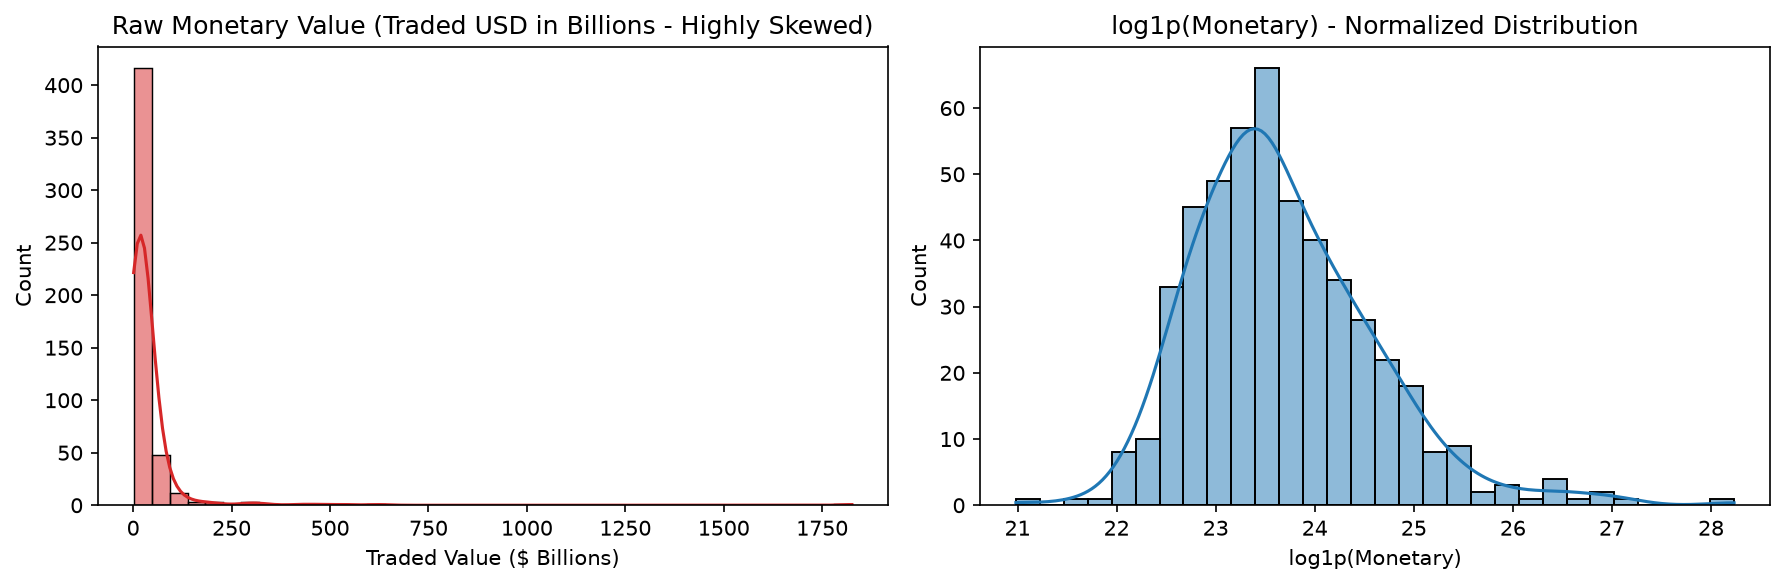

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150)
sns.histplot(features_master["Monetary"] / 1e9, bins=40, kde=True, ax=axes[0], color="#d62728")
axes[0].set_title("Raw Monetary Value (Traded USD in Billions - Highly Skewed)")
axes[0].set_xlabel("Traded Value ($ Billions)")

sns.histplot(features_master["log1p_Monetary"], bins=30, kde=True, ax=axes[1], color="#1f77b4")
axes[1].set_title("log1p(Monetary) - Normalized Distribution")
axes[1].set_xlabel("log1p(Monetary)")
plt.tight_layout()
plt.show()


### 7. Task 2.2: Agglomerative Hierarchical Clustering (Ward Linkage)
Ward linkage with Euclidean distance is fitted independently on:
1. Standardized Risk & Return Matrix (`[Mean_Weekly_Return, Beta]`)
2. Standardized Adapted RFM Matrix (`[Recency, Frequency, log1p_Monetary]`)


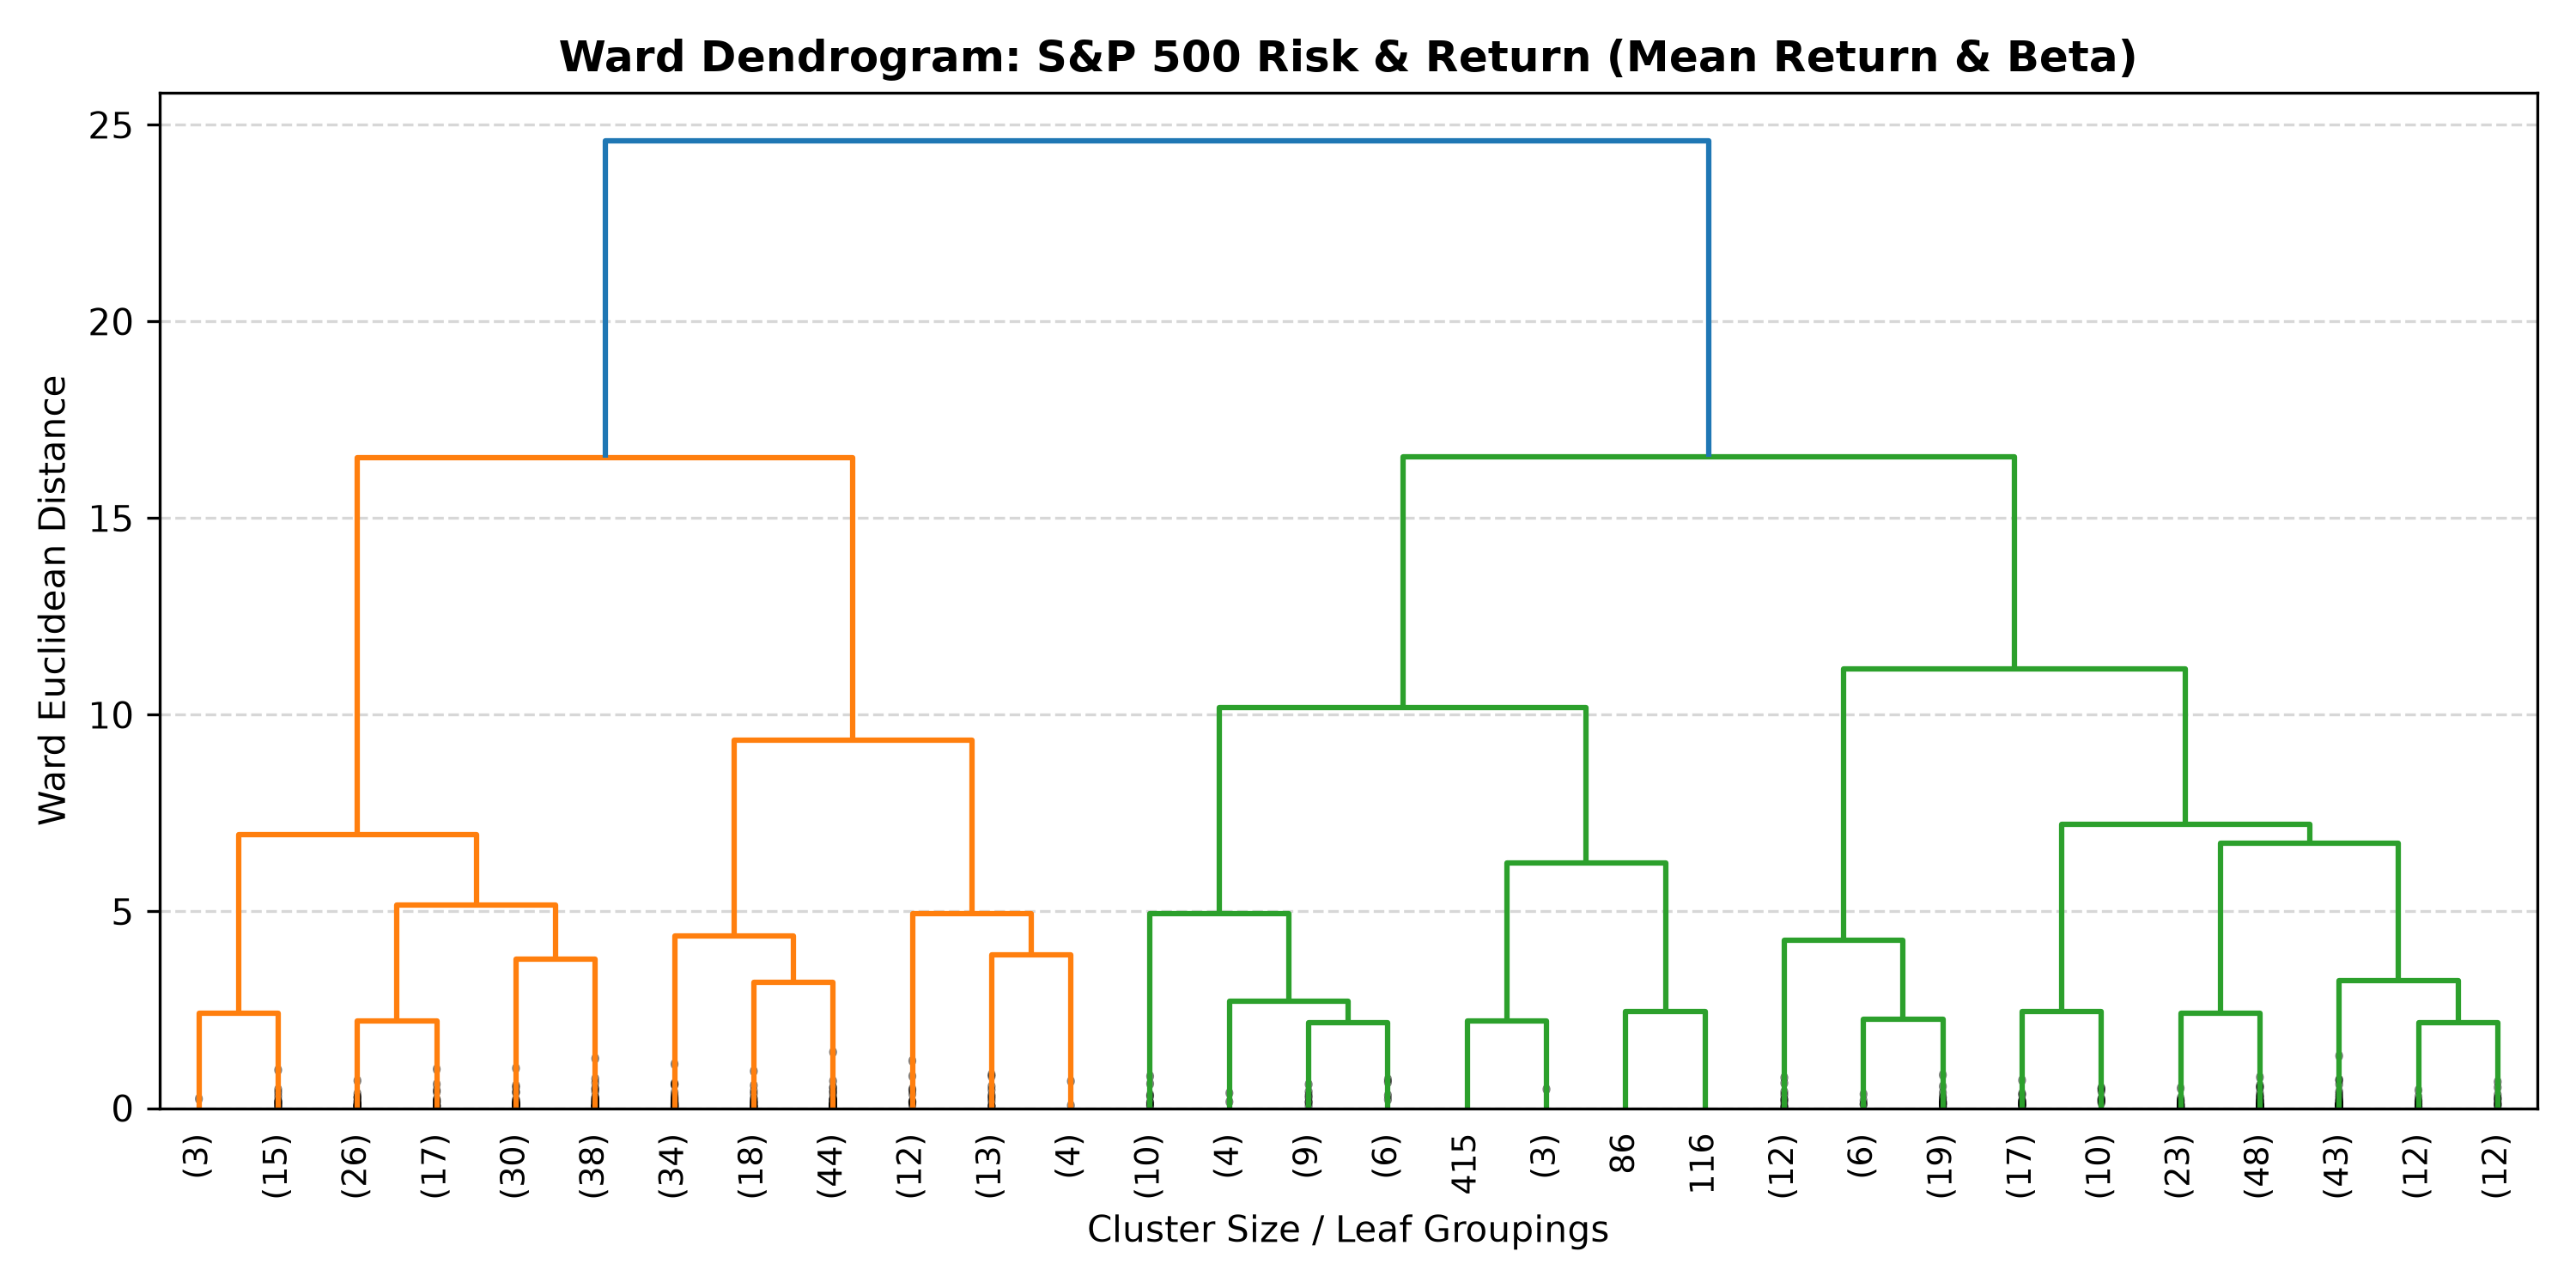

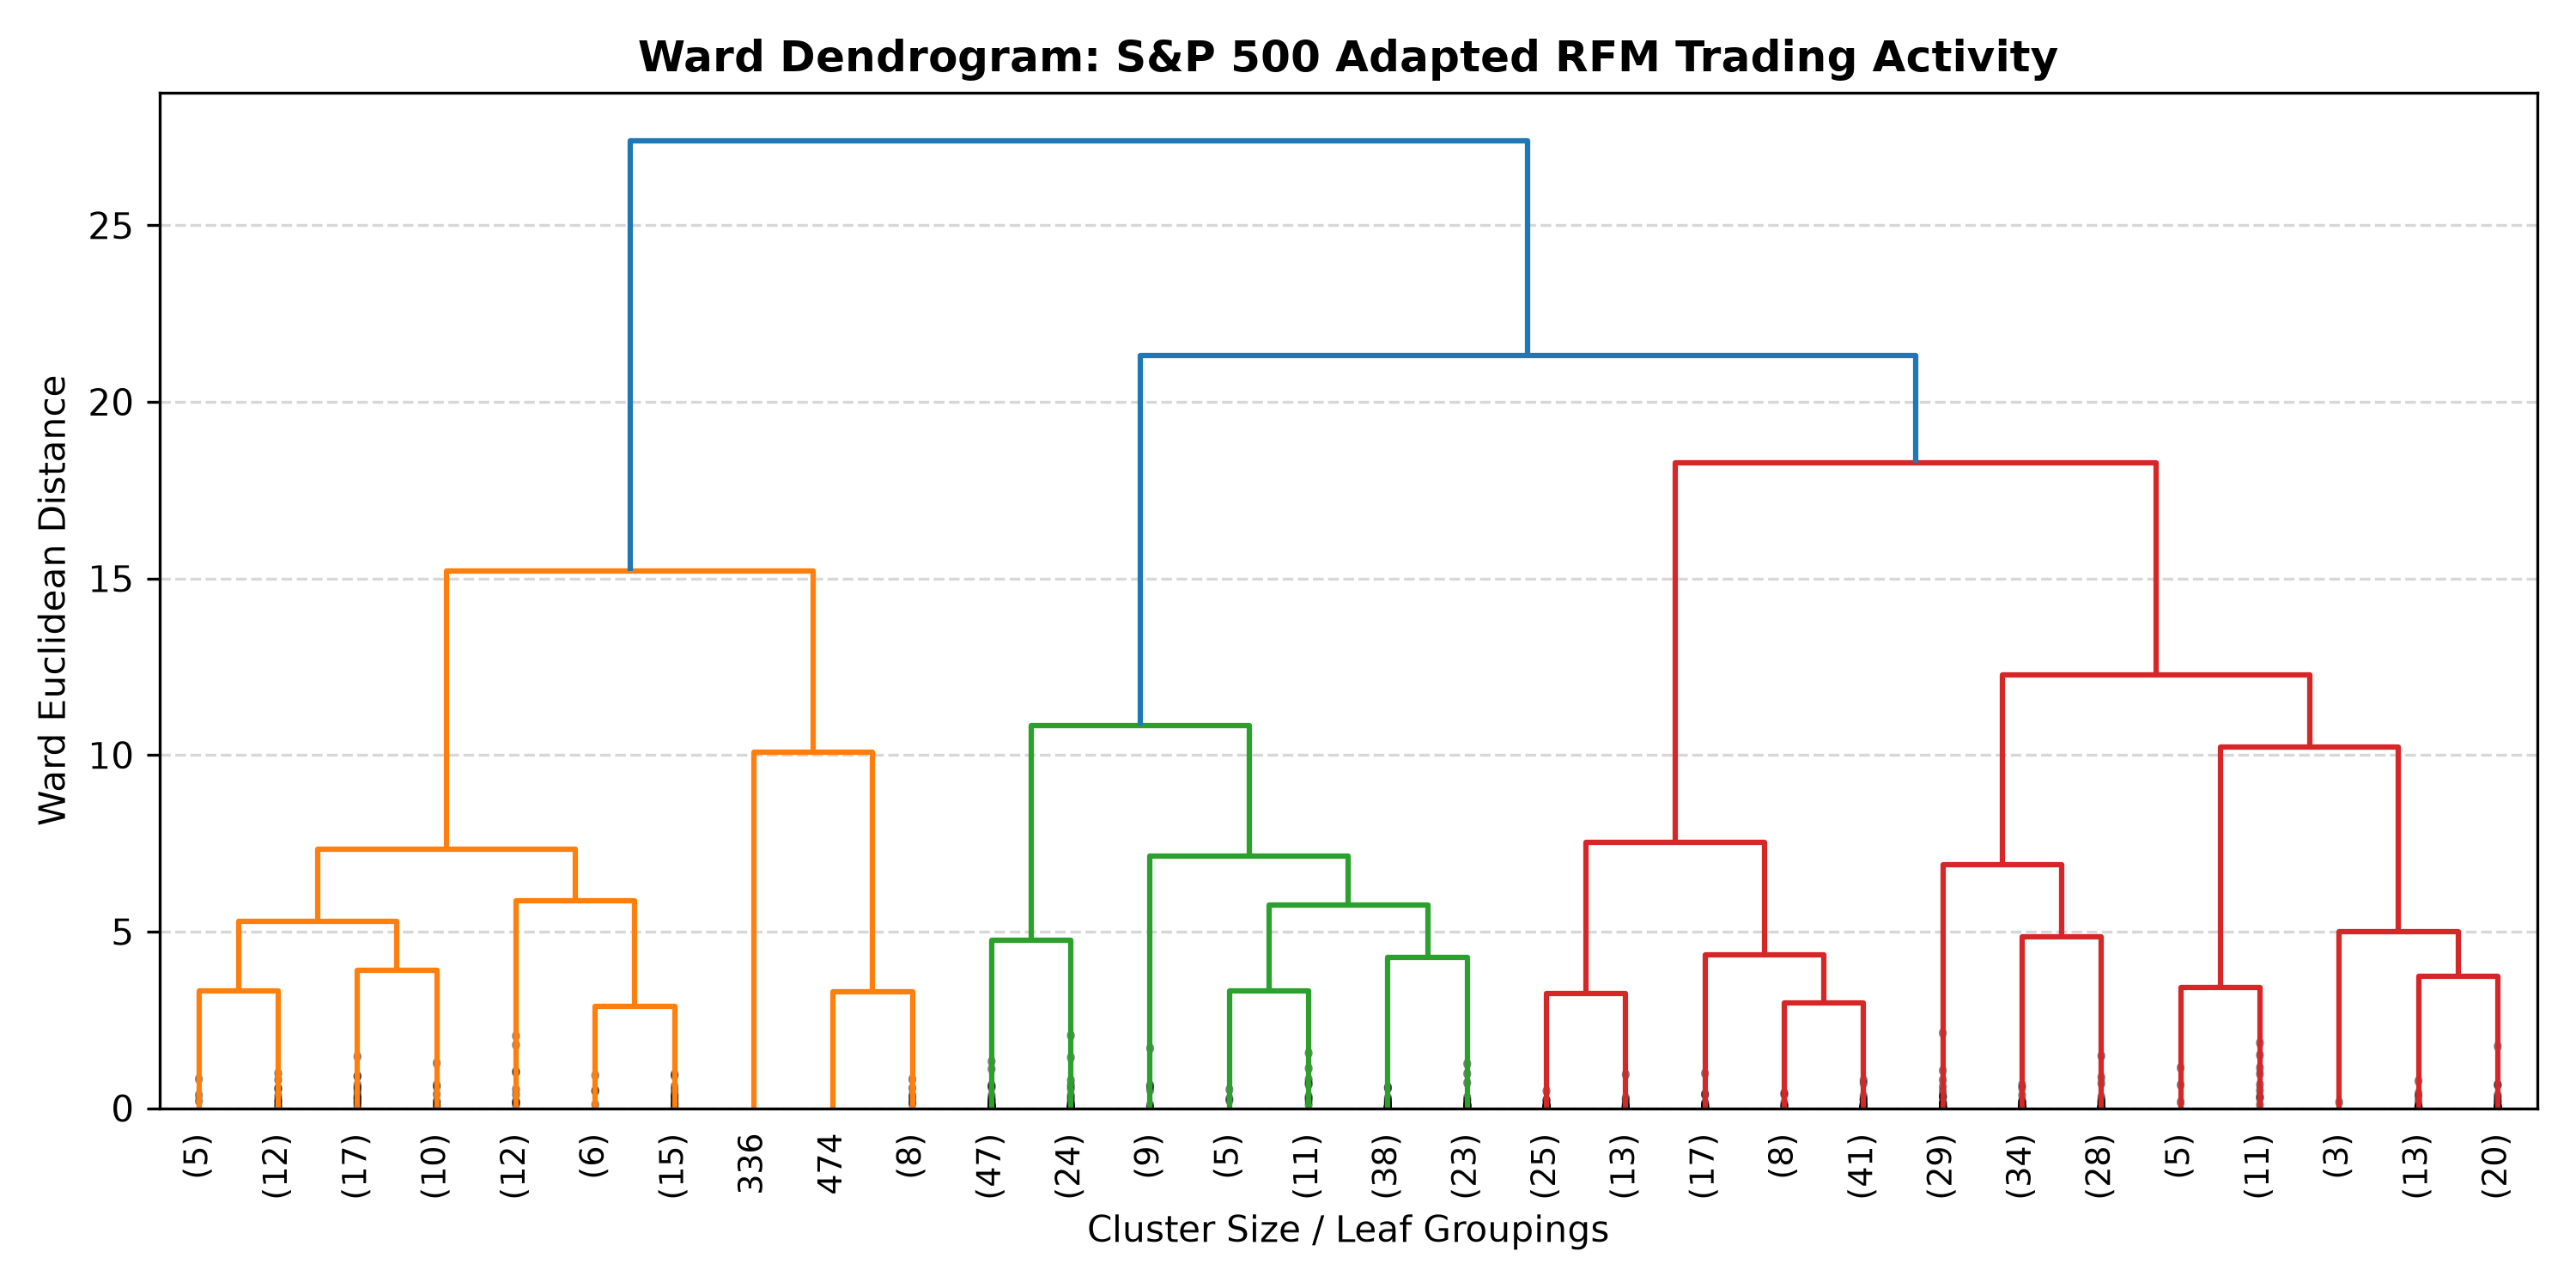

In [8]:
from IPython.display import Image
display(Image("figures/dendrogram_risk_return.png", width=700))
display(Image("figures/dendrogram_rfm.png", width=700))


### 8. Task 2.3: K-Means Clustering & Diagnostics ($k=2..8$)
We assess cluster quality using inertia (Elbow method) and silhouette scores across $k=2..8$ for both feature matrices.


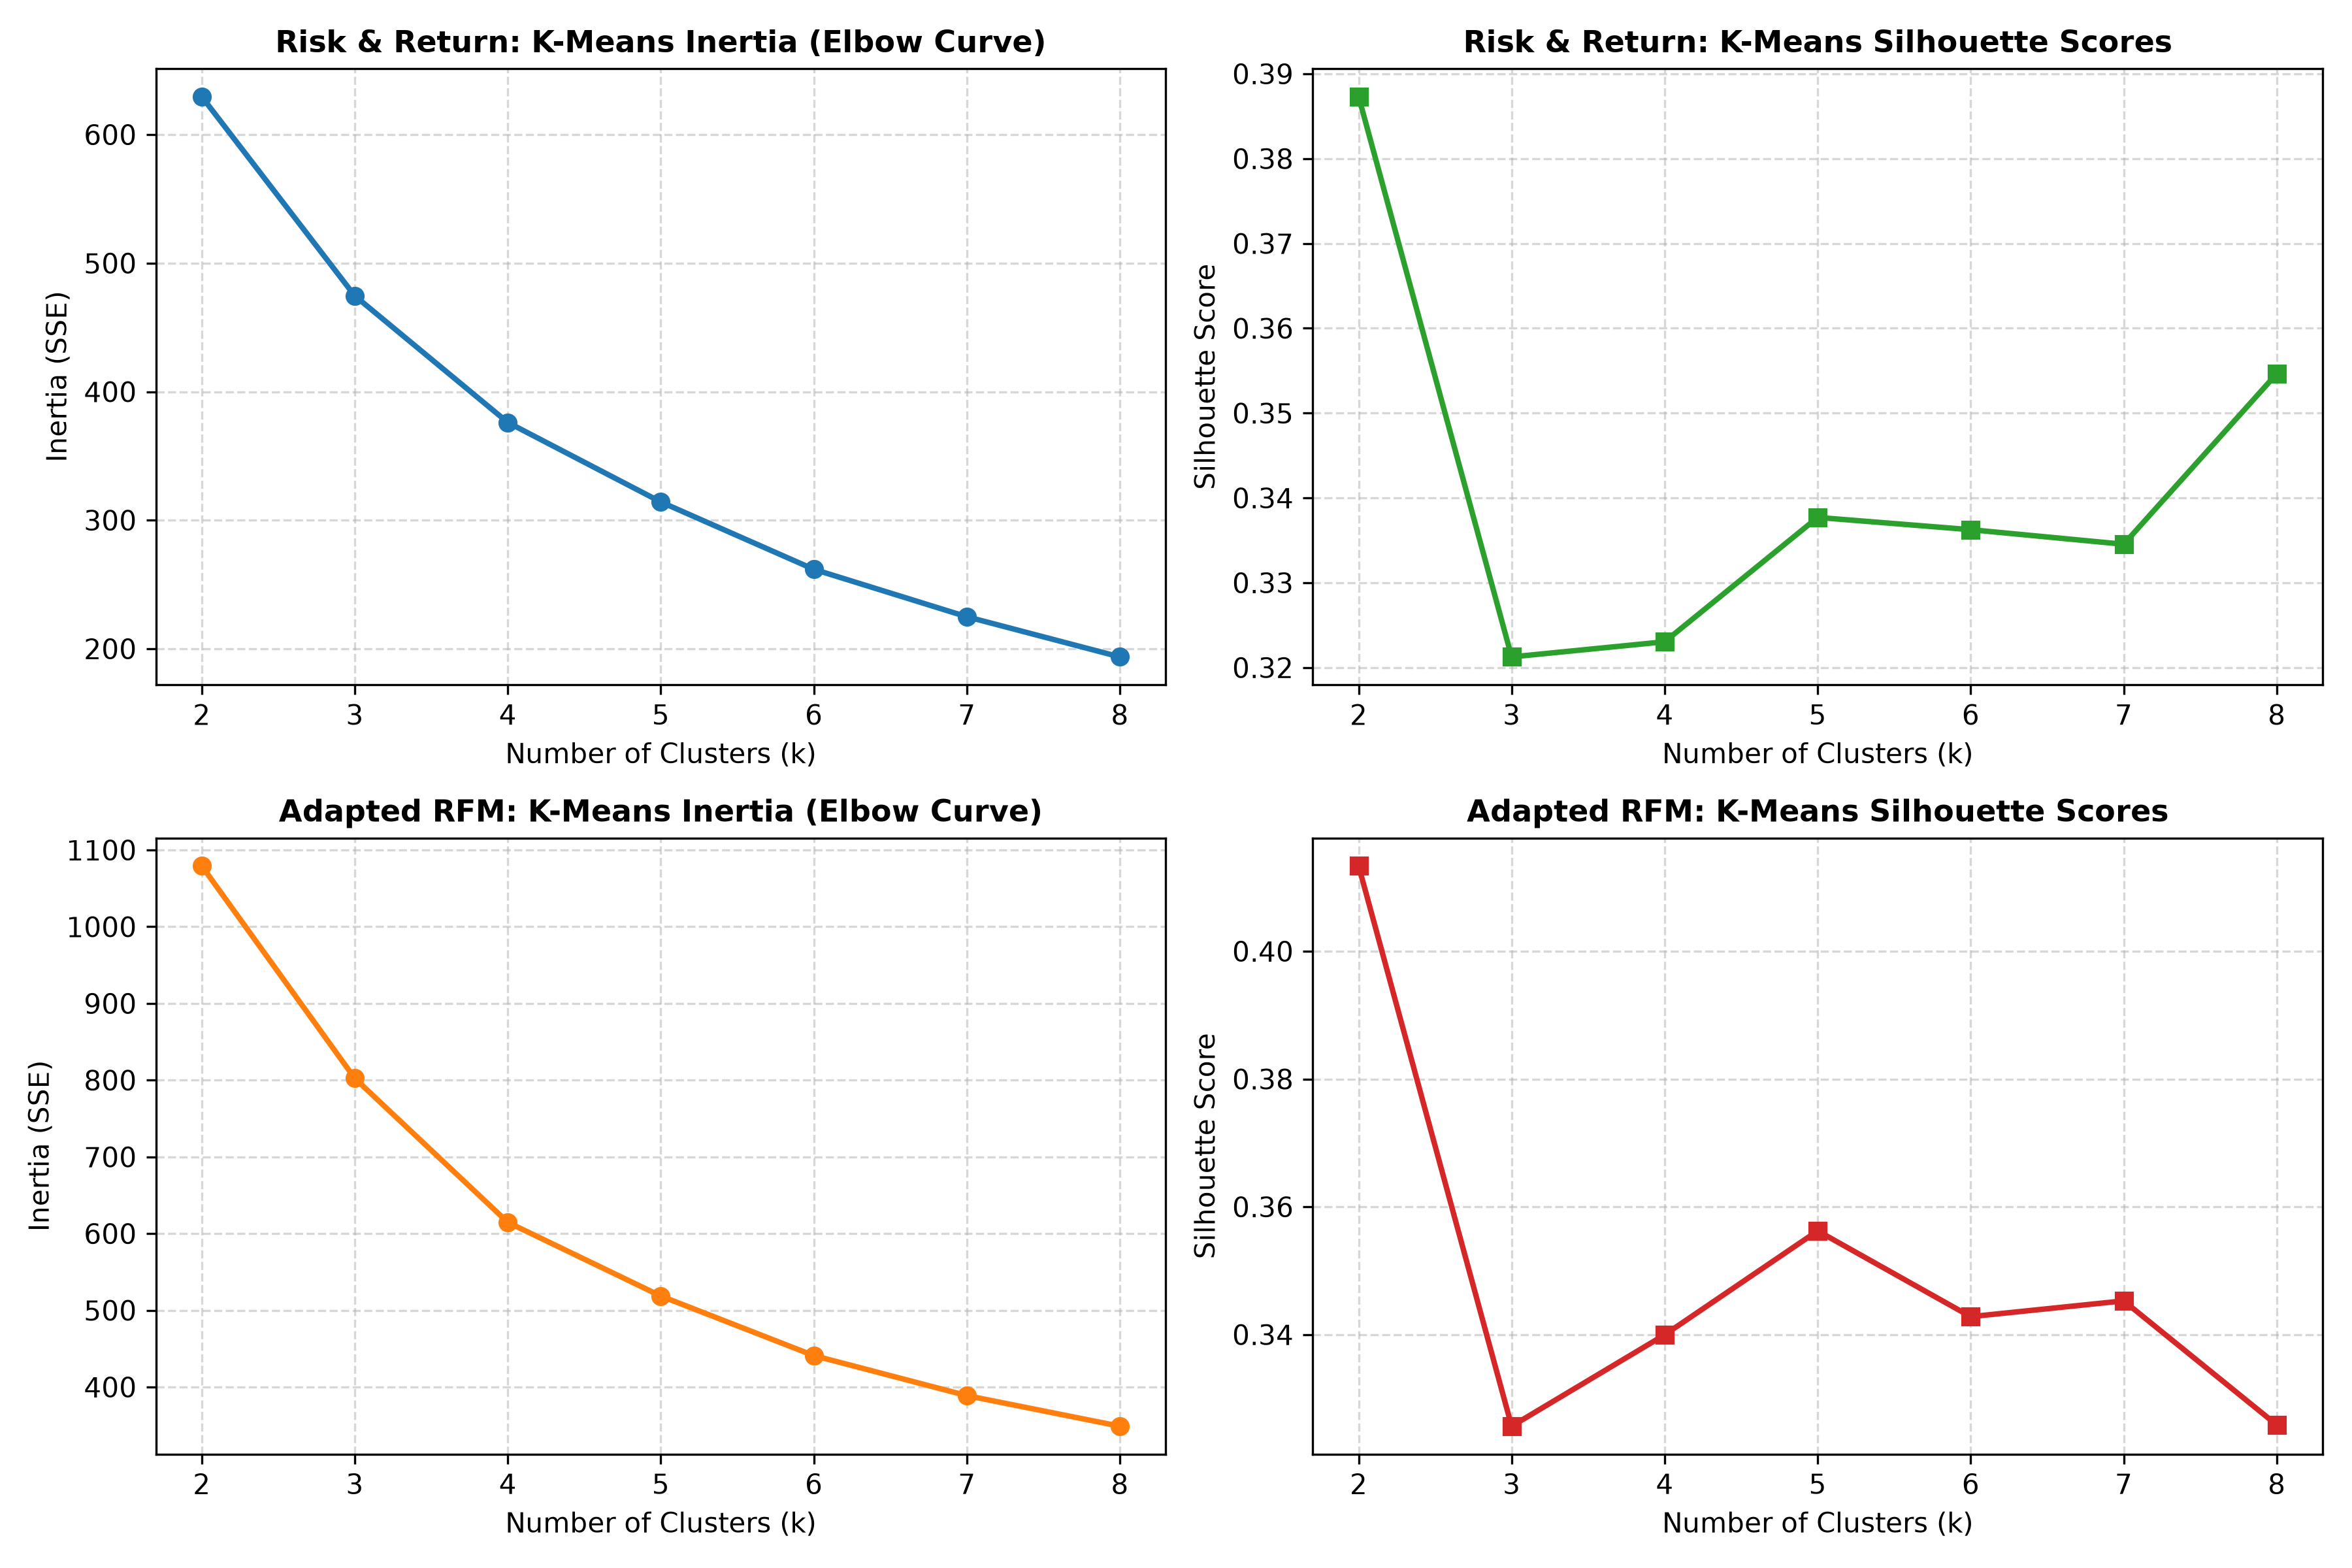

In [9]:
display(Image("figures/cluster_diagnostics.png", width=850))


### 9. Task 2.4: Cluster Profiles & 2D Visualizations
Centroids are reported in original physical units (decimal return, beta, calendar days, count, USD).
A 2D scatter plot displays Risk vs. Return, while PCA projects the 3D RFM space onto 2 principal components.


In [10]:
print("--- Risk & Return Ward Cluster Profiles (k=3) ---")
display(pd.read_csv("data/profile_risk_return.csv"))

print("--- Adapted RFM Ward Cluster Profiles (k=3) ---")
display(pd.read_csv("data/profile_rfm.csv"))


--- Risk & Return Ward Cluster Profiles (k=3) ---


,Ward_Cluster_RR,Return_Mean,Return_Std,Beta_Mean,Beta_Std,Share_Count
0,0,0.001118,0.001636,0.811932,0.368793,254
1,1,0.003951,0.001269,1.091863,0.303041,202
2,2,0.008897,0.002514,1.545600,0.606928,35


--- Adapted RFM Ward Cluster Profiles (k=3) ---


,Ward_Cluster_RFM,Recency_Days_Mean,Recency_Days_Std,Frequency_Mean,Frequency_Std,Traded_Value_USD_Mean,Traded_Value_USD_Std,Share_Count
0,0,11.894737,3.891445,2.655870,1.100164,4.766085e+10,7.720626e+10,247
1,1,56.919540,28.136386,2.000000,1.110206,4.820747e+10,1.939468e+11,87
2,2,13.649682,7.643387,4.070064,1.019770,1.107755e+10,5.335782e+09,157


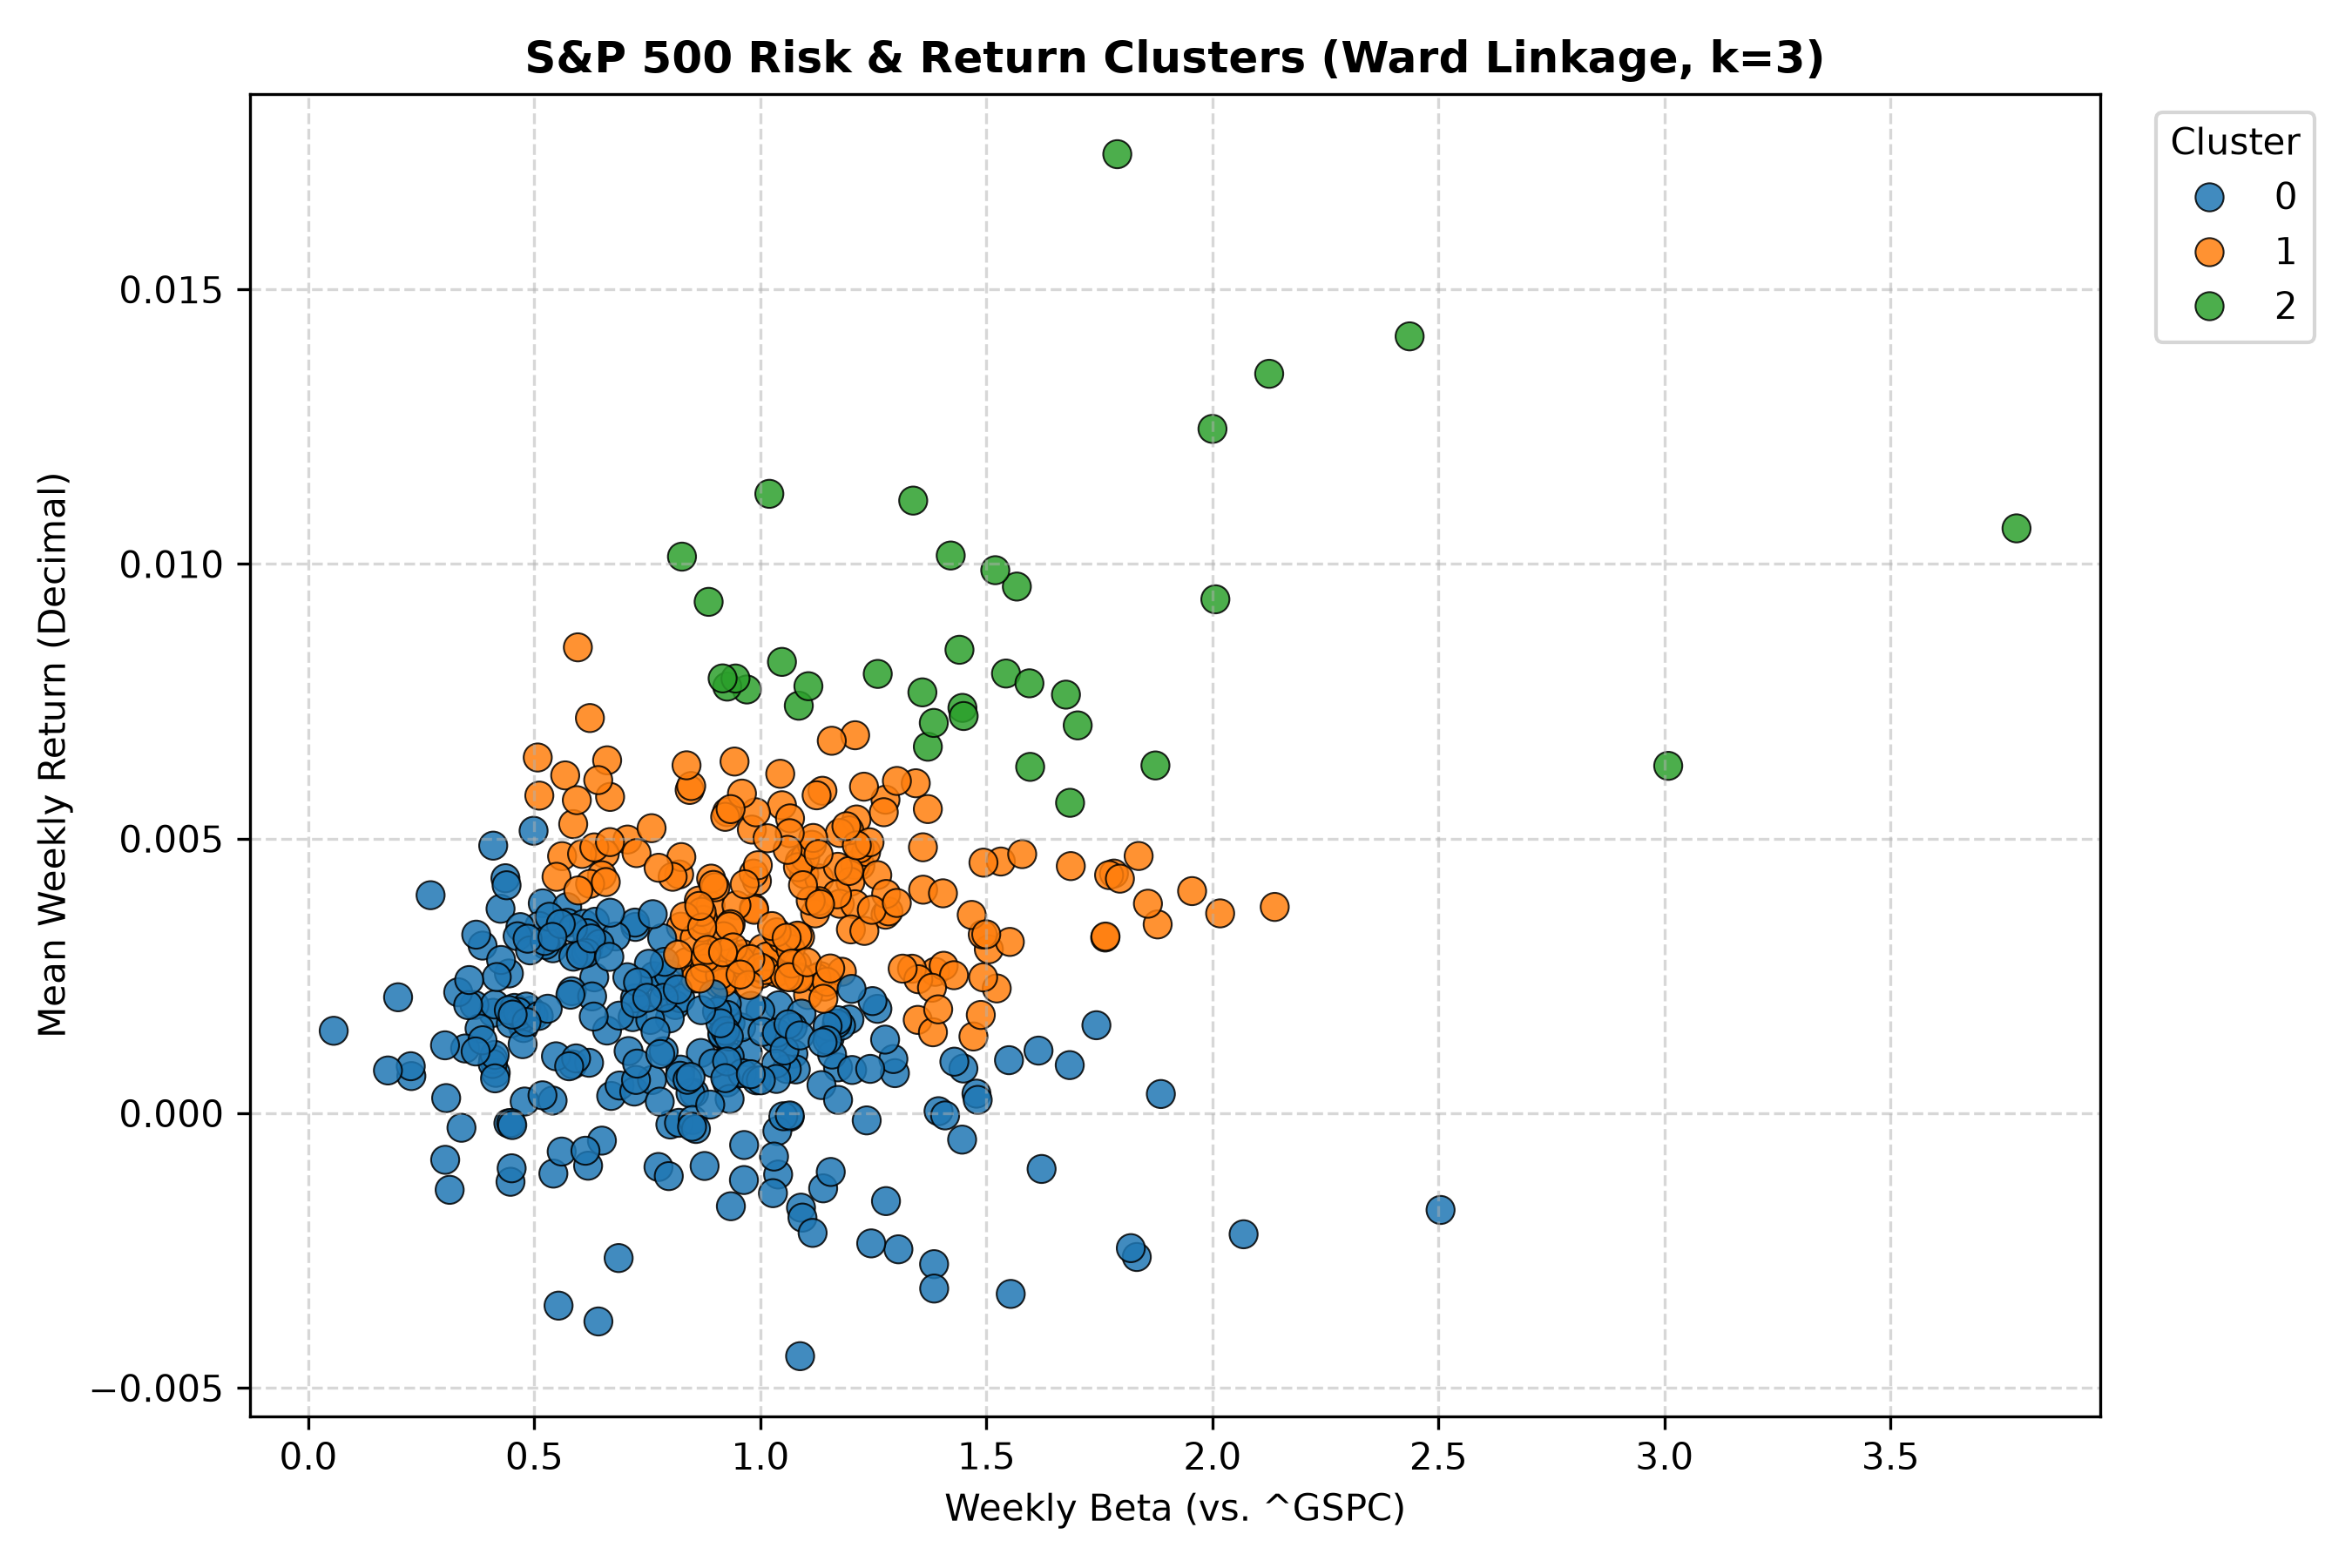

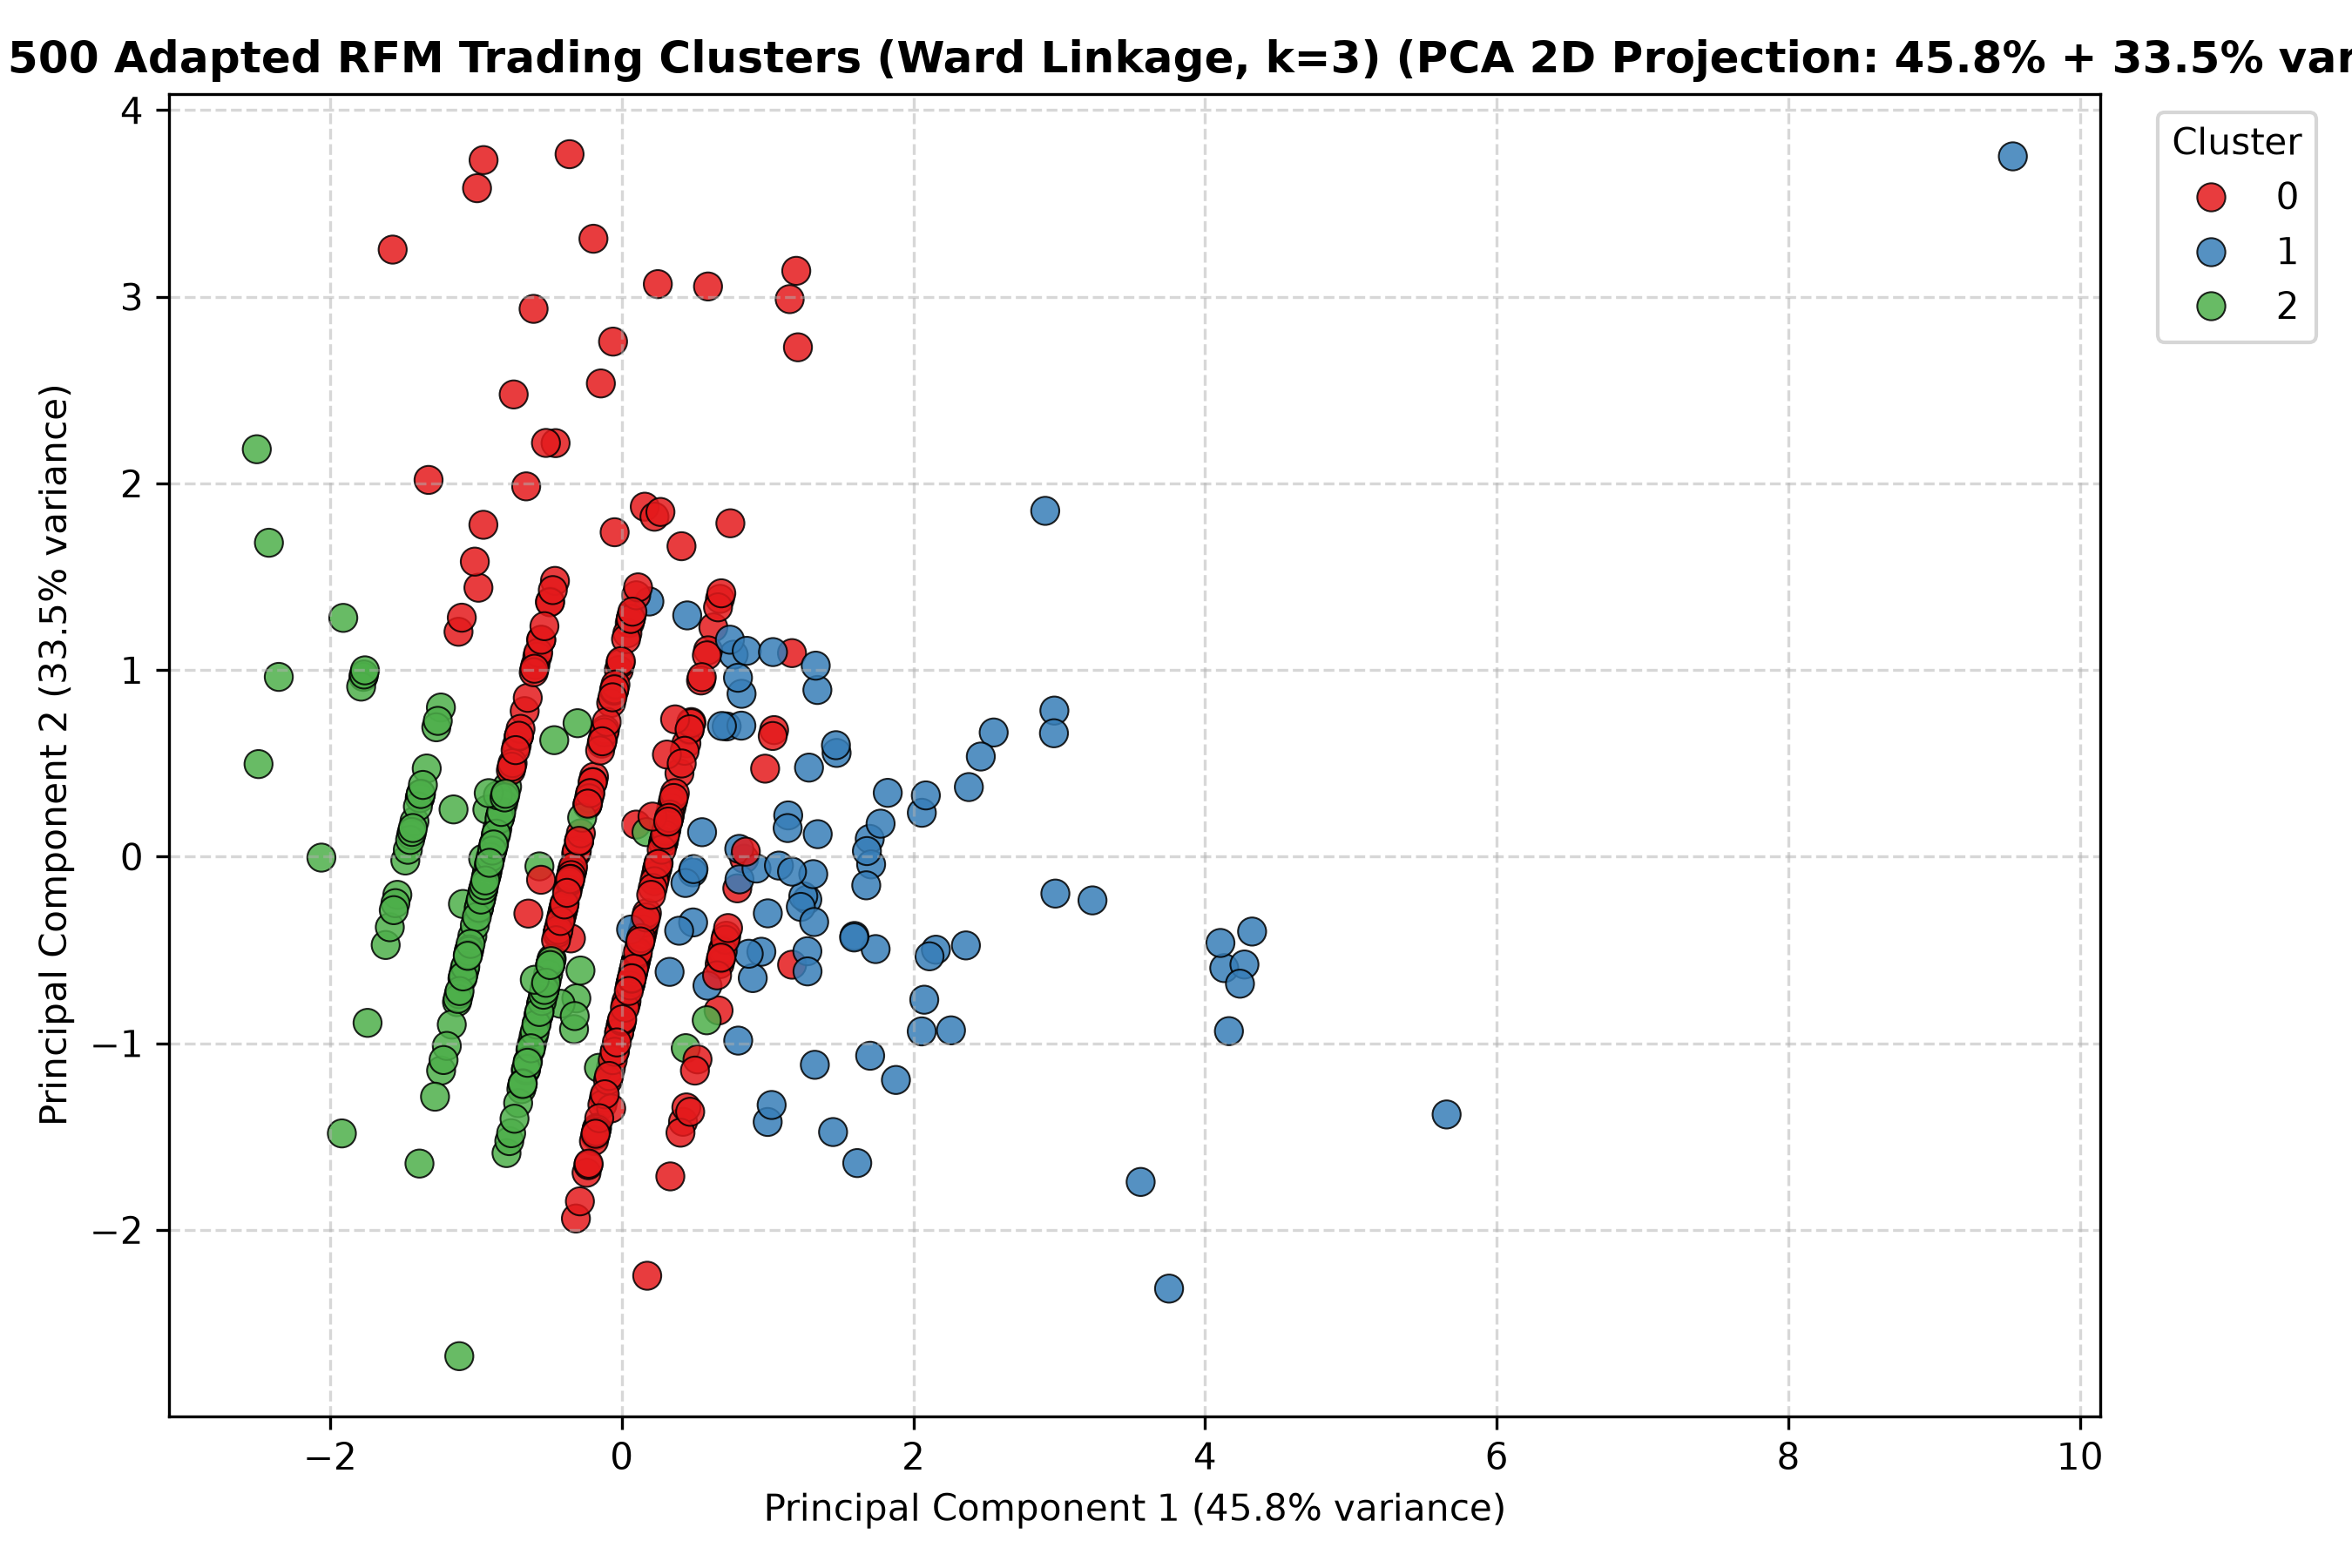

In [11]:
display(Image("figures/scatter_risk_return.png", width=700))
display(Image("figures/scatter_rfm.png", width=700))


### 10. Task 2.5: RFM Sensitivity & Monetary Removal Ablation
1. **Correlation Analysis:** Pearson and Spearman correlations quantify multicollinearity between $R$, $F$, and $\log_{1p}(M)$.
2. **Monetary Removal:** Re-standardizing on $R$ and $F$ alone and refitting Ward clustering ($k=3$) yields an **Adjusted Rand Index (ARI) of 0.3791**, indicating substantial cluster reassignment and proving that Monetary acts primarily as a liquidity/size separator.


Pearson Correlation:


,Recency,Frequency,log1p_Monetary
Recency,1.000000,-0.344719,0.151183
Frequency,-0.344719,1.000000,0.008649
log1p_Monetary,0.151183,0.008649,1.000000


Monetary Removal Ablation Summary:


,Comparison,Adjusted_Rand_Index,Selected_k,Total_Shares
0,RFM (3-feature) vs RF (2-feature),0.37908,3,491


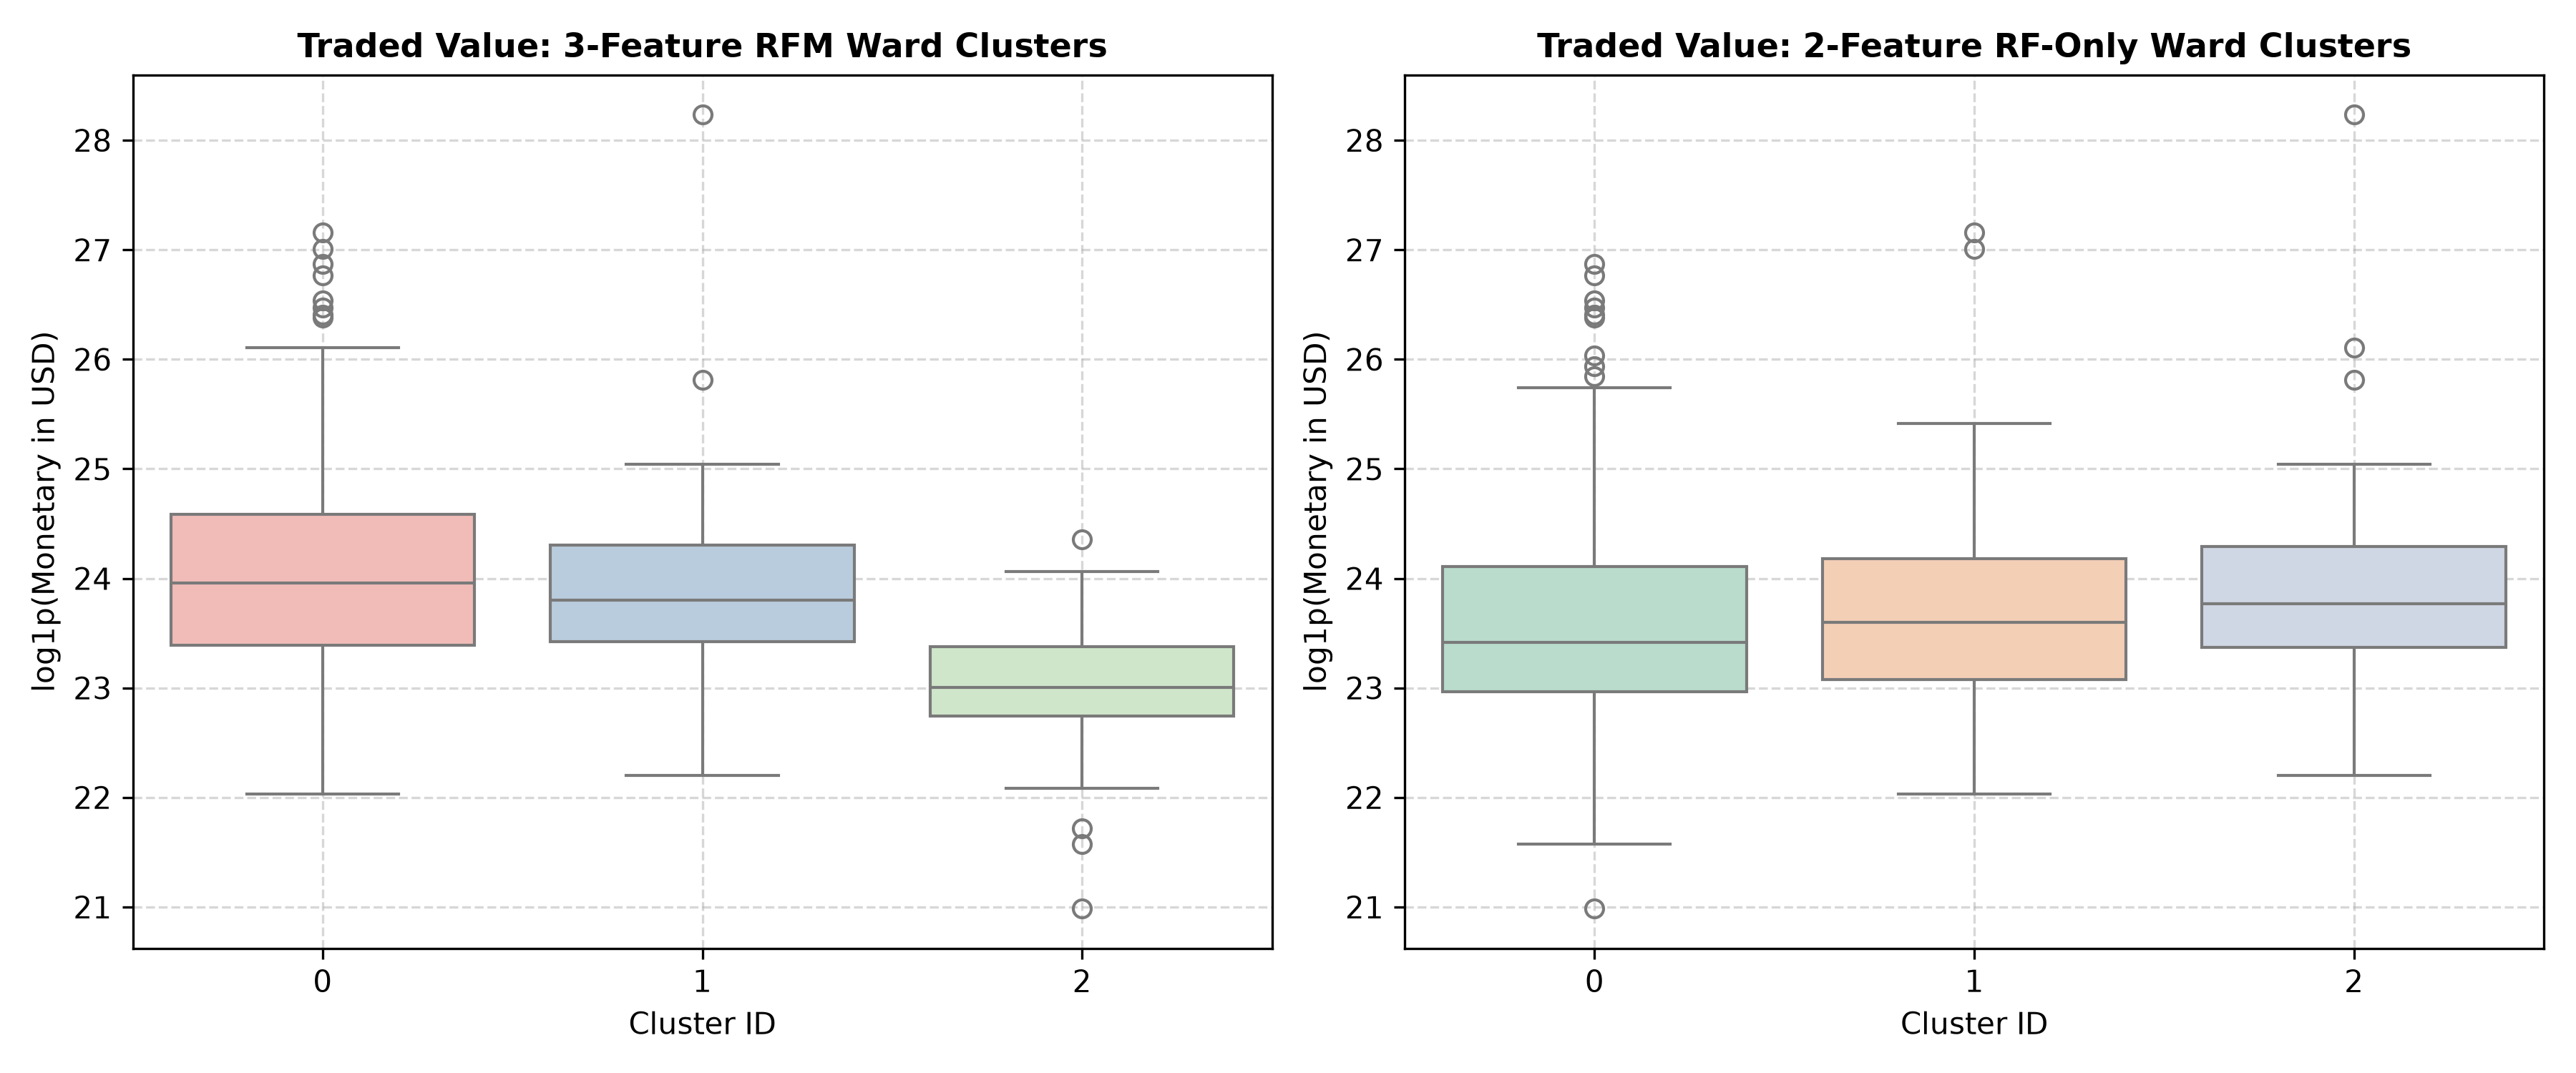

In [12]:
print("Pearson Correlation:")
display(pd.read_csv("data/rfm_correlation_pearson.csv", index_col=0))

print("Monetary Removal Ablation Summary:")
display(pd.read_csv("data/monetary_ablation_ari.csv"))

display(Image("figures/monetary_ablation_distribution.png", width=850))


### 11. Conclusion & BI Integration
The data pipeline exports `cluster_assignments.csv` containing all 4 baseline cluster assignments (Ward & K-Means across both spaces) and sensitivity classifications, ready for dimensional modeling and ingestion into the Business Intelligence Data Mart.


In [13]:
cluster_assignments = pd.read_csv("data/cluster_assignments.csv", index_col="Ticker")
print(f"Final Exported Dataset: {cluster_assignments.shape}")
cluster_assignments[["Company", "GICS_Sector", "Ward_Cluster_RR", "KMeans_Cluster_RR", "Ward_Cluster_RFM", "KMeans_Cluster_RFM", "Ward_Cluster_RF_Only"]].head(10)


Final Exported Dataset: (491, 14)


,Company,GICS_Sector,Ward_Cluster_RR,KMeans_Cluster_RR,Ward_Cluster_RFM,KMeans_Cluster_RFM,Ward_Cluster_RF_Only
Ticker,,,,,,,
MMM,3M,Industrials,0,1,0,0,0
AOS,A. O. Smith,Industrials,0,1,0,0,1
ABT,Abbott Laboratories,Health Care,0,0,0,1,1
ABBV,AbbVie,Health Care,0,0,0,1,0
ACN,Accenture,Information Technology,1,1,0,1,1
ADBE,Adobe Inc.,Information Technology,0,1,0,1,0
AMD,Advanced Micro Devices,Information Technology,1,2,0,1,0
AES,AES Corporation,Utilities,0,1,1,2,2
AFL,Aflac,Financials,1,0,0,0,1
